# Split conformal

Split conformal prediction is the baseline every other method sits on. 
Calibrate on a block of past errors, take a quantile of them, and
add it to the point forecast.

## What it does

Given calibration forecasts and truths, it scores each one — by default with the
absolute residual `s = |y - ŷ|` — and takes the **exact conformal quantile** of
those scores:

```
k = ceil((1 - alpha) * (n + 1))
q = the k-th smallest of s_1 ... s_n
```

The interval is `[ŷ - q, ŷ + q]`. The `n + 1` is not a rounding detail: it is
what makes the coverage guarantee finite-sample rather than asymptotic. With
`n = 24` windows and `alpha = 0.1`, `k = 23`, so `q` is the 23rd smallest of the
24 calibration scores.

One `q` is stored per `(series, horizon)` cell, so the band can widen with the
horizon and differ across a panel even though the score function is shared.

## Worked example

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from statsforecast import StatsForecast
from statsforecast.models import AutoETS

from conformalforecast import SplitConformal
from conformalforecast.adapters import StatsForecastAdapter
from conformalforecast.diagnostics import evaluate

HORIZON, SEASON, ALPHA = 12, 12, 0.1

df = pd.read_csv("nbs/data/air_passengers.csv", parse_dates=["ds"])
panel = df["y"].to_numpy()[None, :]
cutoff = panel.shape[1] - HORIZON
train_df = df.iloc[:cutoff].reset_index(drop=True)

sf = StatsForecast(models=[AutoETS(season_length=SEASON)], freq="MS", n_jobs=1)
sf.fit(train_df)
forecaster = StatsForecastAdapter(
    sf=sf, train_df=train_df, horizon=HORIZON, freq="MS", model_name="AutoETS"
)

method = SplitConformal(alpha=ALPHA)
fitted = method.calibrate_cv(forecaster, n_windows=24)

n = int(fitted.n_calibration_samples_[0])
print(f"n = {n} calibration windows, k = {int(np.ceil((1 - ALPHA) * (n + 1)))}")

n = 24 calibration windows, k = 23


`calibrate_cv` returned a new fitted object and left `method` untouched; its
`score_quantile_` is that `q`, one per `(series, horizon)` cell.
Plotting it against the horizon shows the band widening as the ETS forecast has
more room to drift.

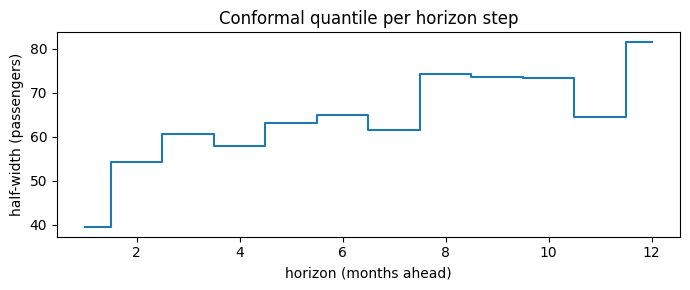

In [ ]:
q = fitted.score_quantile_[0]

fig, ax = plt.subplots(figsize=(7, 3))
ax.step(np.arange(1, HORIZON + 1), q, where="mid", color="C0")
ax.set_xlabel("horizon (months ahead)")
ax.set_ylabel("half-width (passengers)")
ax.set_title("Conformal quantile per horizon step")
fig.tight_layout()

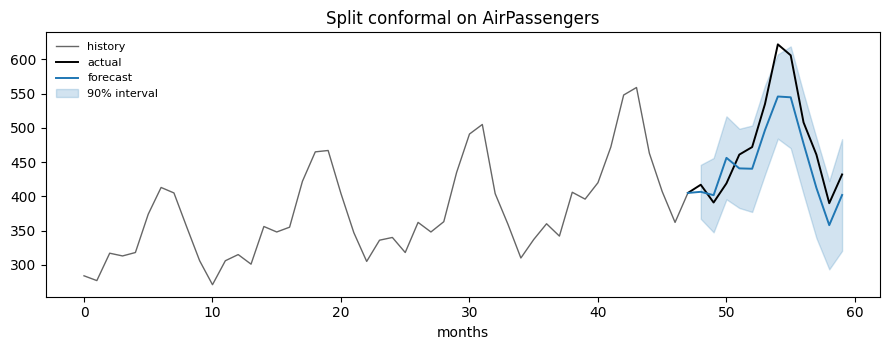

In [ ]:
prediction = fitted.predict(panel[:, :cutoff])

tail = panel[0, cutoff - 48 : cutoff]
past = np.arange(len(tail))
future = np.arange(len(tail), len(tail) + HORIZON)
join = np.r_[past[-1], future]

fig, ax = plt.subplots(figsize=(9, 3.6))
ax.plot(past, tail, color="0.4", lw=1, label="history")
ax.plot(join, np.r_[tail[-1], panel[0, cutoff:]], color="k", lw=1.4, label="actual")
ax.plot(join, np.r_[tail[-1], prediction.point[0, 0]], color="C0", lw=1.4, label="forecast")
ax.fill_between(
    future,
    prediction.interval[0, 0, :, 0],
    prediction.interval[0, 0, :, 1],
    color="C0",
    alpha=0.2,
    label="90% interval",
)
ax.set_title("Split conformal on AirPassengers")
ax.set_xlabel("months")
ax.legend(loc="upper left", fontsize=8, frameon=False)
fig.tight_layout()

## Measured coverage

In [ ]:
N_HOLDOUT = 4
histories, truths = [], []
for k in range(N_HOLDOUT):
    end = panel.shape[1] - (N_HOLDOUT - k) * HORIZON
    histories.append(panel[:, :end])
    truths.append(panel[:, end : end + HORIZON])

report = evaluate(fitted, histories, np.stack(truths, axis=1))
print(report.summary())

Report — SplitConformal
  target coverage: 0.900
  marginal coverage: 0.938
  coverage by horizon: [1.000, 1.000, 1.000, 1.000, 1.000, 1.000, 0.500, 0.750, 1.000, 1.000, 1.000, 1.000]
  mean width: 128.190
  mean Winkler score: 149.198
  n_holdout_samples: 4


## Asymmetric intervals

Everything above builds an equal-width band centred on the forecast, because the
absolute residual `|y - ŷ|` throws away the sign of the error. It targets total
coverage `1 - alpha` and says nothing about how the misses split between the
tails: with skewed residuals one tail can take nearly all of them. And the
symmetric band has a cost: a forecaster that is
*biased* — consistently high or consistently low — can only be covered by
widening the band on both sides, including the side the errors never fall on.

`symmetric=False` scores the **signed** residual `r = y - ŷ` instead and takes
one one-sided conformal quantile per tail:

```
lower_offset = the alpha_lo quantile of r_1 ... r_n
upper_offset = the alpha_hi quantile of the same r
```

with the same `n + 1` correction as before, and the interval becomes
`[ŷ + lower_offset, ŷ + upper_offset]`. Both offsets are stored per
`(series, horizon)` cell, so `score_quantile_` gains a trailing axis of size 2.
Nothing constrains them to be mirror images, so the band can **shift** as well as
widen.

The two levels are bound by `alpha_lo + (1 - alpha_hi) == alpha`: the tails move
against each other on a fixed budget, and both are mandatory once
`symmetric=False`. Setting them to `alpha/2` each — `0.05` and `0.95` here —
gives the equal-tailed interval: the same total `alpha` as the symmetric fit, but
now `alpha/2` per tail, and the band is no longer forced to be centred. The price
is calibration data — each tail needs at least `ceil(2 / alpha)` windows per
series instead of `ceil(1 / alpha)`.

In [ ]:
asym = SplitConformal(alpha=ALPHA, symmetric=False, alpha_lo=0.05, alpha_hi=0.95)
asym_fitted = asym.calibrate_cv(forecaster, n_windows=24)

q_asym = asym_fitted.score_quantile_[0]
print("score_quantile_ shape:", q_asym.shape, "-> (horizon, [lower, upper])\n")

signed = fitted.truths_calibration_ - fitted.predictions_calibration_
print(f"share of calibration residuals above the forecast: {np.mean(signed > 0):.1%}")
print(f"mean signed residual: {np.mean(signed):+.1f} passengers\n")

print(f"{'h':>3}  {'lower':>8} {'upper':>8}  {'width':>7}  {'symmetric':>9}")
for h in (0, 5, 11):
    lo, hi = q_asym[h]
    print(f"{h + 1:>3}  {lo:>8.1f} {hi:>8.1f}  {hi - lo:>7.1f}  {2 * q[h]:>9.1f}")
width_asym, width_sym = q_asym[:, 1] - q_asym[:, 0], 2 * q
print(f"\nmean width  asymmetric {width_asym.mean():.1f}  vs symmetric {width_sym.mean():.1f}")
print(f"narrower at {(width_asym < width_sym).sum()} of {HORIZON} steps")
print(f"highest lower offset: {q_asym[:, 0].max():+.1f} at step {q_asym[:, 0].argmax() + 1}")

score_quantile_ shape: (12, 2) -> (horizon, [lower, upper])

share of calibration residuals above the forecast: 74.3%
mean signed residual: +19.5 passengers

  h     lower    upper    width  symmetric
  1     -22.1     45.1     67.2       78.8
  6     -33.4     68.2    101.6      130.0
 12      -4.4     82.2     86.6      163.2

mean width  asymmetric 102.2  vs symmetric 128.2
narrower at 11 of 12 steps
highest lower offset: -2.5 at step 11


AutoETS under-forecasts AirPassengers, so most calibration residuals land *above* the forecast. The
symmetric band has to reach that far above **and** the same distance below, where
almost nothing falls. The asymmetric band puts its mass where the errors are, and
is narrower at eleven of the twelve steps at the same total `alpha` —
the fourth step is a dead heat, and none of them is meaningfully wider.

The gap is widest at the long end, where the bias has had the most room to
accumulate: at the twelfth step the asymmetric band is barely half the width.

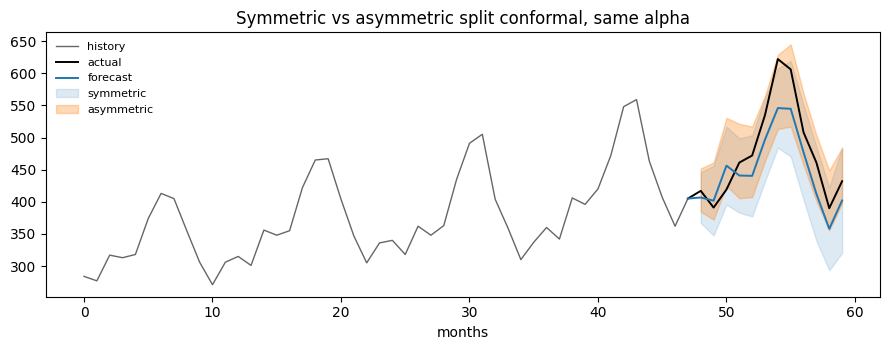

In [ ]:
pred_asym = asym_fitted.predict(panel[:, :cutoff])

fig, ax = plt.subplots(figsize=(9, 3.6))
ax.plot(past, tail, color="0.4", lw=1, label="history")
ax.plot(join, np.r_[tail[-1], panel[0, cutoff:]], color="k", lw=1.4, label="actual")
ax.plot(join, np.r_[tail[-1], prediction.point[0, 0]], color="C0", lw=1.4, label="forecast")
ax.fill_between(
    future,
    prediction.interval[0, 0, :, 0],
    prediction.interval[0, 0, :, 1],
    color="C0",
    alpha=0.15,
    label="symmetric",
)
ax.fill_between(
    future,
    pred_asym.interval[0, 0, :, 0],
    pred_asym.interval[0, 0, :, 1],
    color="C1",
    alpha=0.30,
    label="asymmetric",
)
ax.set_title("Symmetric vs asymmetric split conformal, same alpha")
ax.set_xlabel("months")
ax.legend(loc="upper left", fontsize=8, frameon=False)
fig.tight_layout()

On the same holdout measured earlier:

In [ ]:
asym_report = evaluate(asym_fitted, histories, np.stack(truths, axis=1))
print(asym_report.summary())

Report — SplitConformal
  target coverage: 0.900
  marginal coverage: 0.979
  coverage by horizon: [1.000, 1.000, 0.750, 1.000, 1.000, 1.000, 1.000, 1.000, 1.000, 1.000, 1.000, 1.000]
  mean width: 102.243
  mean Winkler score: 104.610
  n_holdout_samples: 4

Narrower on average and better covered, with a lower Winkler score — which is
the combination that says the symmetric band was paying for width it did not
need. Do not read too much into four holdout windows; the point is the direction,
and the mechanism behind it is visible in the offsets above.

### The calibration data has to stretch further

Each tail is now its own one-sided quantile, so each enforces its own
`ceil(1 / level)` floor. The binding requirement is the stricter of the two:

```
max(ceil(1 / alpha_lo), ceil(1 / (1 - alpha_hi)))
```

For the even split that is `ceil(1 / 0.05) = 20`, comfortably under the 24
windows this page calibrates on. Tilt the budget toward the lower tail and the
floor moves fast:

In [ ]:
from conformalforecast.base import InsufficientCalibrationSamples

try:
    tilted = SplitConformal(alpha=ALPHA, symmetric=False, alpha_lo=0.02, alpha_hi=0.92)
    tilted.calibrate_cv(forecaster, n_windows=24)
except InsufficientCalibrationSamples as err:
    print(f"{type(err).__name__}: {err}")
    print("series:", err.series_indices)

InsufficientCalibrationSamples: Series [0] have fewer than ceil(1/alpha) = 50 effective calibration samples for alpha=0.02 (from alpha_lo=0.02).
series: [0]


`alpha_lo=0.02` needs 50 calibration windows on its own, and the message names
`alpha_lo` rather than quoting the `alpha` you passed — the failing knob is the
one you want to see. Budget for it: an asymmetric interval with a narrow tail
needs several times the calibration data a symmetric one at the same `alpha`
would.

::: {.callout-warning}
## A one-sided interval means the forecaster is biased

If both offsets come out with the same sign, the interval lies entirely above or
entirely below the point forecast, and `fit` warns:

```
Asymmetric split conformal produced an interval lying entirely on one side of
the point forecast. The forecaster is biased on this calibration data; the
interval is shifting rather than widening to compensate.
```

That is not a defect in the method — it is the method reporting one in the
forecaster, and the offsets it produces are still valid. The fit above does not
trip it, but not by much: its highest lower offset is `-2.5`, at the eleventh
step, so a little more drift would put the whole band above the forecast. Fix the
bias in the model if you can; conformalizing around it works, but it spends
interval width on a problem a better point forecast would not have.
:::

Use `symmetric=False` when one tail carries the real cost — inventory, staffing,
capacity — or when the forecaster is biased and you would rather shift than
widen. Stay symmetric otherwise: it needs less calibration data, and an
uninformative tilt just moves coverage around. When the asymmetry depends on the
*features* of each step rather than being a constant offset, that is
[CQR](./cqr.html)'s job, not this one.

## Using the array surface

The forecaster surface did three things above: ran the cross-validation,
converted Nixtla frames to arrays, and called the calibration math. If your
library already owns the first two — which is the case inside statsforecast,
mlforecast and neuralforecast — you want the **array surface**: `fit(predictions, truths)` on the method
returns the same kind of fitted object, and `interval(predictions)` on that
object applies it — no forecaster and no adapter anywhere in the signature.

In [ ]:
# Reuse the calibration arrays the forecaster surface already assembled.
predictions = fitted.predictions_calibration_
observed = fitted.truths_calibration_
print("calibration arrays:", predictions.shape, "(n_series, n_windows, horizon)")

array_fitted = SplitConformal(alpha=ALPHA).fit(predictions, observed)
interval = array_fitted.interval(prediction.point)

print("interval", interval.shape)
np.testing.assert_allclose(interval, prediction.interval)
print("identical to the forecaster-surface result")

calibration arrays: (1, 24, 12) (n_series, n_windows, horizon)
interval (1, 1, 12, 2)
identical to the forecaster-surface result


## When not to use it

- **Your coverage drifts over time.** Split conformal calibrates once and never
  looks again, so a regime change leaves it silently mis-calibrated. Use
  [ACI](./aci.html), [AgACI](./agaci.html) or [NexCP](./nexcp.html).
- **Your errors are strongly heteroscedastic.** The absolute-residual score makes
  one constant-width band per cell. If the noise scales with the level, that band
  is wrong nearly everywhere. Use [CQR](./cqr.html).
- **You need the width itself to be informative.** A constant band cannot say
  "this particular step is unusually uncertain". Use [SPCI](./spci.html).

None of these are reasons to skip split conformal first — it is the measurement
that tells you which of the three problems you actually have.

## References
- H. Papadopoulos, Kostas Proedrou, V. Vovk, and A. Gammerman, “Inductive Confidence Machines for Regression,” pp. 345–356, Jan. 2002, doi: 10.1007/3-540-36755-1_29.
- V. Vovk, A. Gammerman, and G. Shafer, Algorithmic Learning in a Random World. Springer Nature, 2005. doi: 10.1007/b106715.
- J. Lei, M. G’Sell, A. Rinaldo, R. J. Tibshirani, and L. Wasserman, “Distribution-Free Predictive Inference For Regression,” 2016. https://arxiv.org/abs/1604.04173

## Next

- [CQR](./cqr.html) — the other offline method, for heteroscedastic errors.
- [Methods overview](./index.html) — the decision guide.
- [Diagnostics](../capabilities/diagnostics.html) — measuring an interval properly.